In [1]:
import os

import numpy as np
import open3d as o3d
import matplotlib.pyplot as plt

from skimage import filters
from scipy import stats
from sklearn.cluster import KMeans
import pandas as pd

import matplotlib.pyplot as plt
from mpl_toolkits import mplot3d
from copy import copy

from tqdm import tqdm

In [2]:
mesh_database_path = r"../99_broccoli_models"

mesh_db = {}
for file in os.listdir(mesh_database_path):
    if ".obj" in file:
        mesh_db[file[:-4]] = os.path.join(mesh_database_path, file)

In [3]:
def mesh2pcd(mesh):
    mesh_pcd = o3d.geometry.PointCloud()
    mesh_pcd.points = mesh.vertices
    mesh_pcd.colors = mesh.vertex_colors
    mesh_pcd.normals = mesh.vertex_normals
    
    return mesh_pcd

def project_points_on_vector(points, vector):
    """
    把点投影到给定向量上
    输入：points: nx3的三维点
         vector: 1x3的向量
    输出：投影后的点(在空间中的位置)
    """
    v_norm = np.sqrt(sum(vector**2))
    
    return (np.dot(points, vector.reshape(3,1))/v_norm**2)*vector

In [4]:
mesh = o3d.io.read_triangle_mesh(mesh_db['2-33'])

In [5]:
pcd = mesh2pcd(mesh)

Project points on plane

In [6]:
plane = np.array([1, 1, 1])
point = np.array([[2, 3, 4], [4,5,6]])

In [7]:
plane_normal = plane / np.linalg.norm(plane)
plane_normal

array([0.57735027, 0.57735027, 0.57735027])

In [8]:
plane_normal_ext = np.array([plane_normal] * 2)
plane_normal_ext

array([[0.57735027, 0.57735027, 0.57735027],
       [0.57735027, 0.57735027, 0.57735027]])

In [9]:
np.dot(point, plane_normal) 

array([5.19615242, 8.66025404])

In [10]:
np.dot(point, plane_normal)[:, None]

array([[5.19615242],
       [8.66025404]])

In [12]:
np.dot(point, plane_normal)[:, None] * plane_normal

array([[3., 3., 3.],
       [5., 5., 5.]])

In [13]:
point - np.dot(point, plane_normal)[:, None] * plane_normal

array([[-1.0000000e+00, -4.4408921e-16,  1.0000000e+00],
       [-1.0000000e+00, -8.8817842e-16,  1.0000000e+00]])

In [14]:
projection = point - np.dot(point, plane_normal)[:, None] * plane_normal
projection

array([[-1.0000000e+00, -4.4408921e-16,  1.0000000e+00],
       [-1.0000000e+00, -8.8817842e-16,  1.0000000e+00]])

## the easy to used project function

In [19]:
def points_on_plane(points, plane, mode='vector'):
    """
    mode is vector: plane is (3,) array of the normal vector
                  (nx, ny, nz)
    mode is abcd: plane is (4,) array of the plane expression 
                  (A, B, C ,D) -> Ax + By + Cz + D =0
    """
    if mode == 'vector':
        plane_normal = plane / np.linalg.norm(plane)
        projection = points - np.dot(points, plane_normal)[:, None] * plane_normal

        return projection
    else:
        # ref: https://blog.csdn.net/soaryy/article/details/82884691
        # Plane_params = (A, B, C ,D) -> Ax + By + Cz + D =0
        A, B, C, D = plane
        demomin = A**2 + B**2 + C**2
        x0, y0, z0 = points[:,0], points[:,1], points[:,2]
    
        xp = ((B**2+C**2)*x0 - A*(B*y0+C*z0+D)) / demomin
        yp = ((A**2+C**2)*y0 - B*(A*x0+C*z0+D)) / demomin
        zp = ((A**2+B**2)*z0 - C*(A*x0+B*y0+D)) / demomin
    
        return np.vstack([xp, yp, zp]).T


practice on broccoli

In [15]:
# 计算定向边界框
obb = pcd.get_oriented_bounding_box()
obb.color = (0, 0, 0)

In [16]:
main_idx = np.argmax(obb.extent)

In [17]:
p = obb.R[:,main_idx]
xyz = np.asarray(pcd.points)

In [21]:
projected_points = points_on_plane(xyz, p)
projected_points

array([[-0.00058102,  0.00076402, -0.0010139 ],
       [-0.00075233,  0.00229271, -0.00234872],
       [-0.00038224,  0.00256674, -0.00230744],
       ...,
       [ 0.06962159, -0.01190062,  0.058192  ],
       [ 0.06992928, -0.01134201,  0.05796344],
       [ 0.06859735, -0.01175756,  0.05736135]])

In [22]:
projected_pcd = o3d.geometry.PointCloud()
projected_pcd.points = o3d.utility.Vector3dVector(projected_points)
projected_pcd.colors = o3d.utility.Vector3dVector(pcd.colors)

In [23]:
# 坐标轴 RGB -> XYZ
line_set = o3d.geometry.LineSet()

line_set.points = o3d.utility.Vector3dVector(np.array([[0,0,0],[0.1,0,0],[0,0.1,0], [0,0,0.1]]))
line_set.lines = o3d.utility.Vector2iVector([[0,1],[0,2],[0,3]])
line_set.colors = o3d.utility.Vector3dVector(np.array([[1,0,0],[0,1,0],[0,0,1]]))

In [24]:
# 矩阵bbox的正交方向
ur_set = o3d.geometry.LineSet()

ur_set.points = o3d.utility.Vector3dVector(np.array([[0,0,0], obb.R[:,0]/10, obb.R[:,1]/10, obb.R[:,2]/10]))
ur_set.lines = o3d.utility.Vector2iVector([[0,1],[0,2],[0,3]])
ur_set.colors = o3d.utility.Vector3dVector(np.array([[1,1,0],[0,1,1],[1,0,1]]))

In [25]:
o3d.visualization.draw_geometries([pcd, projected_pcd, obb, ur_set])

# Implement New method

In [28]:
def mesh2pcd(mesh):
    mesh_pcd = o3d.geometry.PointCloud()
    mesh_pcd.points = mesh.vertices
    mesh_pcd.colors = mesh.vertex_colors
    mesh_pcd.normals = mesh.vertex_normals
    
    return mesh_pcd

def points_on_vector(points, vector):
    """
    把点投影到给定向量上
    输入：points: nx3的三维点
         vector: 1x3的向量
    输出：投影后的点(在空间中的位置)
    """
    v_norm = np.sqrt(sum(vector**2))
    
    return (np.dot(points, vector.reshape(3,1))/v_norm**2)*vector

def points_on_plane(points, plane, mode='vector'):
    """
    mode is vector: plane is (3,) array of the normal vector
                  (nx, ny, nz)
    mode is abcd: plane is (4,) array of the plane expression 
                  (A, B, C ,D) -> Ax + By + Cz + D =0
    """
    if mode == 'vector':
        plane_normal = plane / np.linalg.norm(plane)
        projection = points - np.dot(points, plane_normal)[:, None] * plane_normal

        return projection
    else:
        # ref: https://blog.csdn.net/soaryy/article/details/82884691
        # Plane_params = (A, B, C ,D) -> Ax + By + Cz + D =0
        A, B, C, D = plane
        demomin = A**2 + B**2 + C**2
        x0, y0, z0 = points[:,0], points[:,1], points[:,2]
    
        xp = ((B**2+C**2)*x0 - A*(B*y0+C*z0+D)) / demomin
        yp = ((A**2+C**2)*y0 - B*(A*x0+C*z0+D)) / demomin
        zp = ((A**2+B**2)*z0 - C*(A*x0+B*y0+D)) / demomin
    
        return np.vstack([xp, yp, zp]).T

def segment_crown(head_pcd, denoise_count=20, denoise_radius=0.01, show_log=False):
    # 计算定向边界框
    obb = head_pcd.get_oriented_bounding_box()
    # find the maximum edge and its vector:
    main_idx = np.argmax(obb.extent)

    # 把点云投影到最长轴上
    # pcd_on_z -> (x, y, z) 3D
    pcd_on_z = project_points_on_vector(np.asarray(head_pcd.points), obb.R[:,main_idx])
    # project 3D line to 1D
    pcd_on_z_unit = (pcd_on_z / obb.R[:,main_idx])[:,0]

    # use Kmeans to classify points to 2 class by color
    rgb = np.asarray(head_pcd.colors)
    kmeans = KMeans(n_clusters=2, random_state=0, n_init=10)
    kmeans.fit(rgb)

    ## the z axis points of each class
    z0 = pcd_on_z_unit[kmeans.labels_ == 0]
    z1 = pcd_on_z_unit[kmeans.labels_ == 1]
    z0_mean = z0.mean()
    z1_mean = z1.mean()

    # find out which is the crown class
    ## calculate the direction
    pmax = pcd_on_z_unit.max()
    pmin = pcd_on_z_unit.min()
    pmid = (pmax + pmin) / 2
    pmean = pcd_on_z_unit.mean()

    if pmean < pmid:
        # The crown is in the -z direction (points KDE line)
        #
        # |        pmean
        # |       . |    pmid
        # |     .   |  . ||
        # |   .     |    ||  .  
        # | .       |    ||       ^   .
        # o-------------------------------> +z
        
        if z0_mean < z1_mean:
            # print('z0 is crown')
            crown_bool_idx = kmeans.labels_ == 0
        else:
            # print('z1 is crown')
            crown_bool_idx = kmeans.labels_ == 1
    else:
        # The crown is in the +z direction (points KDE line)
        #
        # |                 pmean
        # |            pmid   |  .
        # |             ||  . |    .
        # |           . ||    |      .
        # | .     ^     ||    |        .
        # o-------------------------------> +z
        
        # vz is the crown Z direction vertex
        vz = obb.R[:,main_idx] * -1
        if z0_mean < z1_mean:
            # print('z1 is crown')
            crown_bool_idx = kmeans.labels_ == 1
        else:
            # print('z0 is crown')
            crown_bool_idx = kmeans.labels_ == 0

    crown_int_idx = np.where(crown_bool_idx)[0]

    crown_pcd = head_pcd.select_by_index(crown_int_idx)
    # crown_pcd_denoised, keeped_int_idx = crown_pcd.remove_radius_outlier(denoise_count, denoise_radius)
    # crown_pcd_denoised, keeped_int_idx = crown_pcd.remove_statistical_outlier(denoise_count, denoise_radius)
    crown_pcd_denoised, keeped_int_idx = remove_dbscan_outlier(crown_pcd, denoise_count, denoise_radius, show_log)
    crown_denoised_int_idx = crown_int_idx[keeped_int_idx]

    ## create a results pcd, 
    labeled_pcd = o3d.geometry.PointCloud()

    ### black for stem
    label_rgb = np.zeros((len(head_pcd.points), 3))
    ### red for denoised
    label_rgb[crown_bool_idx, :] = np.array([1,0,0])
    ### green for crown
    label_rgb[crown_denoised_int_idx,:] = np.array([0,1,0])

    labeled_pcd.points = o3d.utility.Vector3dVector(head_pcd.points)
    labeled_pcd.colors = o3d.utility.Vector3dVector(label_rgb)

    #################
    ## draw figures
    #################
    if show_log:
        kde0 = stats.gaussian_kde(z0)
        xx0 = np.linspace(pmin, pmax, 1000)
        yy0 = kde0(xx0)

        kde1 = stats.gaussian_kde(z1)
        xx1 = np.linspace(pmin, pmax, 1000)
        yy1 = kde1(xx1)

        fig, ax = plt.subplots(1,1)
        ax.plot(xx0, yy0,color='b', label='z0')
        ax.plot(xx1, yy1,color='g', label='z1')

        ax.axvline(x=pmid, color='r', label="middle")

        ax.axvline(x=z0_mean, color='b', label="z0mean")
        ax.axvline(x=z1_mean, color='g',label="z1mean")

        plt.legend()
        plt.show()

    return crown_pcd_denoised, labeled_pcd, crown_denoised_int_idx

#====================

def remove_dbscan_outlier(pcd, min_points, eps, show_log=False):
    label = pcd.cluster_dbscan(eps=eps, min_points=min_points, print_progress=True)
    db_labels, db_count = np.unique(label, return_counts=True)

    if len(db_count) <= 2:  # already splited by [-1 ,0]
        broccoli_crown_cluster_idx = [0]
    else:
        # calculate the cluster size as another reference
        characters = np.empty((len(db_count), 2))
        for i, (l, c) in enumerate(zip(db_labels, db_count)):
            idx_on_label = np.where(label==l)[0]
            pcd_on_label = pcd.select_by_index(idx_on_label)
            volume = _calculate_xyz_volume(pcd_on_label)

            characters[i-1, 0] = c
            characters[i-1, 1] = volume

        # print("charectors:\n",characters)
        # Kmeans cluster
        km = KMeans(n_clusters=2, n_init=10)
        km.fit(characters)

        class0 = characters[km.labels_ == 0, :]
        class1 = characters[km.labels_ == 1, :]

        # print("class0, class1\n", class0, '\n', class1)
        # find the class label with largest point clouds (broccoli_crowns)
        if class0.mean(axis=0)[0] > class1.mean(axis=0)[0]:
            broccoli_crown_cluster_idx = np.where(km.labels_ == 0)[0]
        else:
            plant_cluster_idx = np.where(km.labels_ == 1)[0]

        if show_log: print(f"DBSCAN\nlabel - count\n{np.vstack([db_labels, db_count]).T}\nUse {plant_cluster_idx} as plants")
        plant_id = []
        for idx in plant_cluster_idx:
            # print(idx, label, np.where(np.array(label)==idx)[0])
            plant_id += np.where(np.array(label)==idx)[0].tolist()

        # print("plant_id\n", plant_id)

        return pcd.select_by_index(plant_id), plant_id

def _calculate_xyz_volume(pcd):
    pcd_xyz = np.asarray(pcd.points)

    x_len = pcd_xyz[:, 0].max() - pcd_xyz[:, 0].min()
    y_len = pcd_xyz[:, 1].max() - pcd_xyz[:, 1].min()
    z_len = pcd_xyz[:, 2].max() - pcd_xyz[:, 2].min()

    return x_len * y_len * z_len


# ==============================
def rotate_to_z(crown_pcd, original_pcd):
    obb = crown_pcd.get_oriented_bounding_box()
    
    # find out the closest vector to orginal broccoli longest axis
    # clamp_angle_sin = []
    # angle_list = []
    # for i in range(0, 3):
    #     angle = angle2(vz, obb.R[:, i])
    #     angle_list.append(angle)
    #     clamp_angle_sin.append(np.sin(np.deg2rad(angle)))

    # main_idx = np.argmin(np.asarray(clamp_angle_sin))
    # if angle_list[main_idx] < 90:
    #     main_direction = obb.R[:, main_idx] * -1
    # else:
    #     main_direction = obb.R[:, main_idx]

    

    R = get_rotation_matrix(get_unit_vector(main_direction), (0,0,1))
    pcd_rotated = copy(original_pcd).rotate(R, center=obb.center)

    return pcd_rotated, R


def angle2(v1, v2):
    x=np.array(v1)
    y=np.array(v2)

    # 分别计算两个向量的模：
    module_x=np.sqrt(x.dot(x))
    module_y=np.sqrt(y.dot(y))

    # 计算两个向量的点积
    dot_value=x.dot(y)

    # 计算夹角的cos值：
    cos_theta=dot_value/(module_x*module_y)

    # 求得夹角（弧度制）：
    angle_radian=np.arccos(cos_theta)

    # 转换为角度值：
    angle_value=angle_radian*180/np.pi
    return angle_value

def get_unit_vector(v):
    return v / np.linalg.norm(v)

def get_rotation_matrix(a, b):
    v = np.cross(a, b)
    s = np.dot(a, b)
    vx = np.array([[0, -v[2], v[1]],
                   [v[2], 0, -v[0]],
                   [-v[1], v[0], 0]])
    R = np.identity(3) + vx + np.dot(vx, vx) * (1 / (1 + s))

    return R


# ===========================================
def draw_rotated(xyz_o, rgb_o, xyz_r, rgb_r, save_path, show=True):
    fig = plt.figure(figsize=(15, 10), dpi=300)
    ax1 = fig.add_subplot(231, projection='3d')
    ax2 = fig.add_subplot(232, projection='3d')
    ax3 = fig.add_subplot(233, projection='3d')
    ax4 = fig.add_subplot(234, projection='3d')
    ax5 = fig.add_subplot(235, projection='3d')
    ax6 = fig.add_subplot(236, projection='3d')

    for ax in [ax1, ax2, ax3]:
        ax.scatter(*xyz_o.T, c=rgb_o, marker='.', alpha=0.5, s=1)
        ax.set_xlabel('X')
        ax.set_ylabel('Y')
        ax.set_zlabel('Z')

        ax.set_box_aspect((np.ptp(xyz_o[:,0]), np.ptp(xyz_o[:,1]), np.ptp(xyz_o[:,2])))

    for ax in [ax4, ax5, ax6]:
        ax.scatter(*xyz_r.T, c=rgb_r, marker='.', alpha=0.5, s=1)
        ax.set_xlabel('X')
        ax.set_ylabel('Y')
        ax.set_zlabel('Z')
        ax.set_box_aspect((np.ptp(xyz_r[:,0]), np.ptp(xyz_r[:,1]), np.ptp(xyz_r[:,2])))

    ax1.view_init(elev=0, azim=45)
    ax2.view_init(elev=0, azim=165)
    ax3.view_init(elev=0, azim=285)
    ax4.view_init(elev=0, azim=45)
    ax5.view_init(elev=0, azim=165)
    ax6.view_init(elev=0, azim=285)

    ax1.set_title('45 degree azim')
    ax2.set_title('165 degree azim')
    ax3.set_title('285 degree azim')

    plt.tight_layout()
    plt.savefig(save_path)
    if show:
        plt.show()
    else:
        plt.cla()
        plt.clf()
        del fig, ax1, ax2, ax3, ax4, ax5, ax6

In [29]:
broccoli_id = '3-4'

bro_mesh = o3d.io.read_triangle_mesh(mesh_db[broccoli_id])

def_test_pcd = mesh2pcd(bro_mesh)

crown_pcd, crown_colored_pcd, crown_points_index = segment_crown(def_test_pcd, 10, 0.005, show_log=False)

# rotated_pcd, R = rotate_to_z(crown_pcd, def_test_pcd, vz)

Modify `rotate_to_z`

In [30]:
obb = crown_pcd.get_oriented_bounding_box()

In [41]:
# get the projections on each plane
project_0 = points_on_plane(xyz, obb.R[:, 0])
project_1 = points_on_plane(xyz, obb.R[:, 1])
project_2 = points_on_plane(xyz, obb.R[:, 2])
project_0

array([[-0.00039801,  0.01897881,  0.00806432],
       [-0.00135716,  0.02001912,  0.00715393],
       [-0.00124919,  0.02059505,  0.00757187],
       ...,
       [ 0.05398426,  0.00630782,  0.08076188],
       [ 0.05388653,  0.00678887,  0.08083983],
       [ 0.05321443,  0.00649017,  0.07973414]])

In [43]:
projected_pcd0 = o3d.geometry.PointCloud()
projected_pcd0.points = o3d.utility.Vector3dVector(project_0)
projected_pcd0.colors = o3d.utility.Vector3dVector(pcd.colors)

projected_pcd1 = o3d.geometry.PointCloud()
projected_pcd1.points = o3d.utility.Vector3dVector(project_1)
projected_pcd1.colors = o3d.utility.Vector3dVector(pcd.colors)

projected_pcd2 = o3d.geometry.PointCloud()
projected_pcd2.points = o3d.utility.Vector3dVector(project_2)
projected_pcd2.colors = o3d.utility.Vector3dVector(pcd.colors)

# 矩阵bbox的正交方向
ur_set = o3d.geometry.LineSet()

ur_set.points = o3d.utility.Vector3dVector(np.array([[0,0,0], obb.R[:,0]/10, obb.R[:,1]/10, obb.R[:,2]/10]))
ur_set.lines = o3d.utility.Vector2iVector([[0,1],[0,2],[0,3]])
ur_set.colors = o3d.utility.Vector3dVector(np.array([[1,1,0],[0,1,1],[1,0,1]]))

o3d.visualization.draw_geometries([projected_pcd0, projected_pcd1, projected_pcd2, ur_set])

In [44]:
obb.center

array([-0.02615859,  0.10181098, -0.71808978])

In [45]:
vx = get_unit_vector(obb.R[:, 1])
vy = get_unit_vector(obb.R[:, 2])

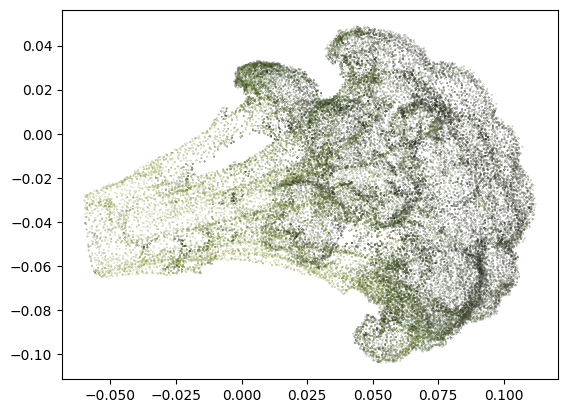

In [49]:
plt.scatter(np.dot(project_0, vx), np.dot(project_0, vy), color=np.asarray(pcd.colors), marker='.', s=0.1)
plt.show()

In [50]:
for i in range(3):
    print(i, (i+1)%3, (i+2)%3)

0 1 2
1 2 0
2 0 1


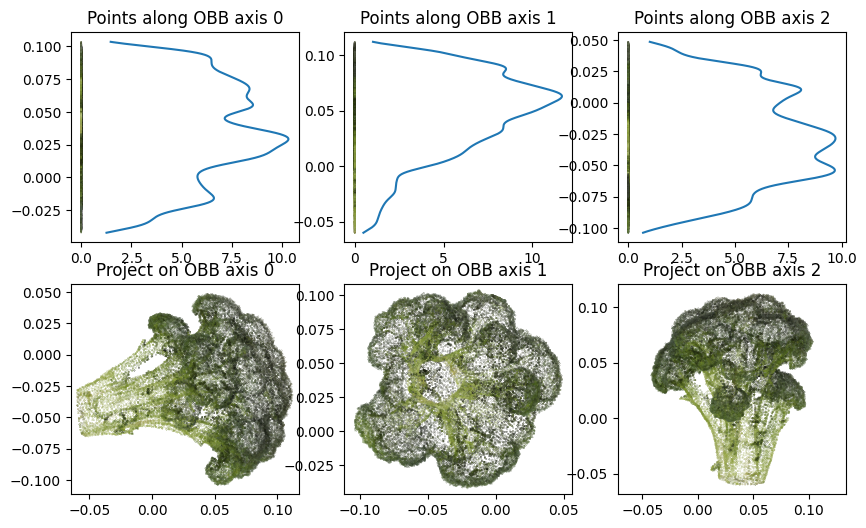

In [73]:
fig, ax = plt.subplots(2,3, figsize=(10,6))

for i in range(3):
    project_0 = points_on_plane(xyz, obb.R[:, i])

    vx = get_unit_vector(obb.R[:, (i+1)%3])
    vy = get_unit_vector(obb.R[:, (i+2)%3])

    x0 = np.dot(project_0, vx)
    y0 = np.dot(project_0, vy)

    xy = np.vstack([x0, y0]).T

    ax[1, i].scatter(x0, y0, color=np.asarray(pcd.colors), marker='.', s=0.1)
    ax[1, i].axis('equal')

    ax[1, i].set_title(f"Project on OBB axis {i}")

    # convex hull
    hull = ConvexHull(xy)
    hull_xy = xy[hull.vertices, :]

    # the vector itself
    vz = points_on_vector(xyz, obb.R[:, i])
    z0 = (vz / obb.R[:,i])[:,0]
    kde = stats.gaussian_kde(z0)
    xx = np.linspace(z0.min(), z0.max(), 1000)
    yy = kde(xx)

    ax[0, i].scatter(np.zeros(z0.shape), z0, color=np.asarray(pcd.colors), marker='.', s=0.1)
    ax[0, i].plot(yy, xx)

    ax[0, i].set_title(f"Points along OBB axis {i}")

plt.show()

In [62]:
from scipy.spatial import ConvexHull
from skimage.measure import regionprops

from geometry.min_bounding_rect import min_bounding_rect
from geometry.fit_ellipse import fit_ellipse

import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from mpl_toolkits.mplot3d import Axes3D
import mpl_toolkits.mplot3d.art3d as art3d

In [80]:
def pcd2binary_2d(xy, dpi=10):
    # dpi suggest < 20
    # !!!! notice !!!!
    # in numpy image system, Y axis is 0, X axis is 1
    y = xy[:, 0]
    x = xy[:, 1]

    x_length_m = x.max() - x.min()
    y_length_m = y.max() - y.min()
    px_num_per_cm = int(dpi / 2.54)
    width = int(np.ceil(x_length_m * 100 * px_num_per_cm))
    height = int(np.ceil(y_length_m * 100 * px_num_per_cm))
    ref_x = (x - x.min()) / x_length_m * width
    ref_y = (y - y.min()) / y_length_m * height
    ref_pos = np.vstack([ref_x, ref_y]).T.astype(int)
    ref_pos_rm_dup = np.unique(ref_pos, axis=0)

    out_img = np.zeros((width + 1, height + 1))
    out_img[ref_pos_rm_dup[:, 0], ref_pos_rm_dup[:, 1]] = 1
    out_img = out_img.astype(int)

    left_top_corner = (y.min(), x.min())

    return out_img, px_num_per_cm, left_top_corner

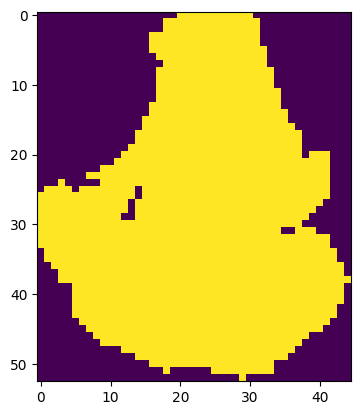

In [81]:
out_img, px_num_per_cm, left_top_corner = pcd2binary_2d(xy)
px_num_per_cm, left_top_corner

regions = regionprops(out_img)

plt.imshow(out_img)
plt.show()

In [83]:
props = regions[0] 
props

 'area',
 'area_bbox',
 'area_convex',
 'area_filled',
 'axis_major_length',
 'axis_minor_length',
 'bbox',
 'centroid',
 'centroid_local',
 'centroid_weighted',
 'centroid_weighted_local',
 'coords',
 'coords_scaled',
 'eccentricity',
 'equivalent_diameter_area',
 'euler_number',
 'extent',
 'feret_diameter_max',
 'image',
 'image_convex',
 'image_filled',
 'image_intensity',
 'inertia_tensor',
 'inertia_tensor_eigvals',
 'intensity_max',
 'intensity_mean',
 'intensity_min',
 'label',
 'moments',
 'moments_central',
 'moments_hu',
 'moments_normalized',
 'moments_weighted',
 'moments_weighted_central',
 'moments_weighted_hu',
 'moments_weighted_normalized',
 'num_pixels',
 'orientation',
 'perimeter',
 'perimeter_crofton',
 'slice',
 'solidity']

In [85]:
props.eccentricity

0.6368484014271527

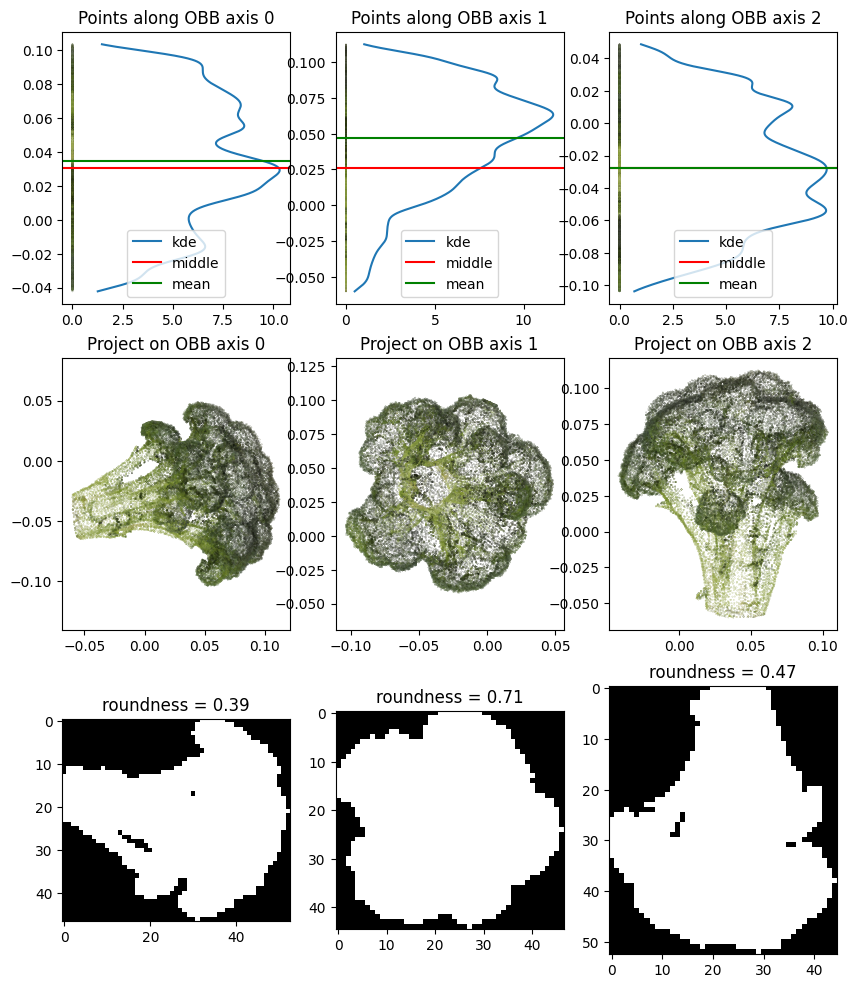

In [98]:
fig, ax = plt.subplots(3,3, figsize=(10,12))

roundness = []
direction = []
for i in range(3):
    project_0 = points_on_plane(xyz, obb.R[:, i])

    vx = get_unit_vector(obb.R[:, (i+1)%3])
    vy = get_unit_vector(obb.R[:, (i+2)%3])

    x0 = np.dot(project_0, vx)
    y0 = np.dot(project_0, vy)

    xy = np.vstack([x0, y0]).T

    ax[1, i].scatter(x0, y0, color=np.asarray(pcd.colors), marker='.', s=0.1)
    ax[1, i].axis('equal')

    ax[1, i].set_title(f"Project on OBB axis {i}")

    # the vector itself
    vz = points_on_vector(xyz, obb.R[:, i])
    z0 = (vz / obb.R[:,i])[:,0]
    zmin = z0.min()
    zmax = z0.max()
    zmid = (z0.min() + z0.max()) / 2
    zmean = z0.mean()
    kde = stats.gaussian_kde(z0)
    xx = np.linspace(zmin, zmax, 1000)
    yy = kde(xx)

    if zmean > zmid:
        direction.append(1)
    else:
        direction.append(-1)

    ax[0, i].scatter(np.zeros(z0.shape), z0, color=np.asarray(pcd.colors), marker='.', s=0.1)
    ax[0, i].plot(yy, xx, label='kde')
    ax[0, i].axhline(y=zmid, color='r', label='middle')
    ax[0, i].axhline(y=zmean, color='g', label='mean')

    ax[0, i].set_title(f"Points along OBB axis {i}")
    ax[0, i].legend(loc='lower center')

    out_img, px_num_per_cm, left_top_corner = pcd2binary_2d(xy)
    regions = regionprops(out_img)
    props = regions[0]
    ratio = 4 * np.pi * props.area / ( props.perimeter**2 )
    ax[2, i].imshow(out_img, cmap='gray')
    ax[2, i].set_title(f"roundness = {round(ratio, 2)}")

    roundness.append(ratio)
    
plt.show()

In [99]:
top_idx = np.array(roundness).argmax()
top_idx

1

In [109]:
def pcd2binary_2d(xy, dpi=10):
    # dpi suggest < 20
    # !!!! notice !!!!
    # in numpy image system, Y axis is 0, X axis is 1
    y = xy[:, 0]
    x = xy[:, 1]

    x_length_m = x.max() - x.min()
    y_length_m = y.max() - y.min()
    px_num_per_cm = int(dpi / 2.54)
    width = int(np.ceil(x_length_m * 100 * px_num_per_cm))
    height = int(np.ceil(y_length_m * 100 * px_num_per_cm))
    ref_x = (x - x.min()) / x_length_m * width
    ref_y = (y - y.min()) / y_length_m * height
    ref_pos = np.vstack([ref_x, ref_y]).T.astype(int)
    ref_pos_rm_dup = np.unique(ref_pos, axis=0)

    out_img = np.zeros((width + 1, height + 1))
    out_img[ref_pos_rm_dup[:, 0], ref_pos_rm_dup[:, 1]] = 1
    out_img = out_img.astype(int)

    left_top_corner = (y.min(), x.min())

    return out_img, px_num_per_cm, left_top_corner


def rotate_to_z(crown_pcd, original_pcd, show=False, save_path=None):
    obb = crown_pcd.get_oriented_bounding_box()

    xyz = np.asarray(original_pcd.points)
    rgb = np.asarray(original_pcd.colors)

    if save_path is not None or show: 
        fig, ax = plt.subplots(3,3, figsize=(10,12))

    roundness = []
    direction = []
    for i in range(3):
        project_0 = points_on_plane(xyz, obb.R[:, i])

        # get the projected points on the xy coordiantes
        vx = get_unit_vector(obb.R[:, (i+1)%3])
        vy = get_unit_vector(obb.R[:, (i+2)%3])

        x0 = np.dot(project_0, vx)
        y0 = np.dot(project_0, vy)

        xy = np.vstack([x0, y0]).T

        # the vector itself, find the direction
        vz = points_on_vector(xyz, obb.R[:, i])
        z0 = (vz / obb.R[:,i])[:,0]
        zmin = z0.min()
        zmax = z0.max()
        zmid = (z0.min() + z0.max()) / 2
        zmean = z0.mean()
        kde = stats.gaussian_kde(z0)
        xx = np.linspace(zmin, zmax, 1000)
        yy = kde(xx)

        if zmean > zmid:
            direction.append(1)
        else:
            direction.append(-1)

        # calculate the roundness
        out_img, px_num_per_cm, left_top_corner = pcd2binary_2d(xy)
        regions = regionprops(out_img)
        props = regions[0]
        ratio = 4 * np.pi * props.area / ( props.perimeter**2 )
        roundness.append(ratio)

        if save_path is not None or show: 
            ax[0, i].scatter(np.zeros(z0.shape), z0, color=rgb, marker='.', s=0.1)
            ax[0, i].plot(yy, xx, label='kde')
            ax[0, i].axhline(y=zmid, color='r', label='middle')
            ax[0, i].axhline(y=zmean, color='g', label='mean')
            ax[0, i].set_title(f"Points along OBB axis {i}")
            ax[0, i].legend(loc='lower center')

            ax[1, i].scatter(x0, y0, color=rgb, marker='.', s=0.1)
            ax[1, i].axis('equal')
            ax[1, i].set_title(f"Project on OBB axis {i}")

            ax[2, i].imshow(out_img, cmap='gray')
            ax[2, i].set_title(f"roundness = {round(ratio, 2)}")

    main_idx = np.array(roundness).argmax()

    main_direction = obb.R[:, main_idx] * direction[main_idx]

    R = get_rotation_matrix(get_unit_vector(main_direction), (0,0,1))
    pcd_rotated = copy(original_pcd).rotate(R, center=obb.center)

    if save_path is not None or show: 
        # set the main direction to red color
        for i in range(3):
            ax[i, main_idx].tick_params(color='green', labelcolor='green')
            for spine in ax[i, main_idx].spines.values():
                spine.set_edgecolor('red')

    if show: 
        plt.show()
    else: 
        plt.savefig(save_fig)

    plt.cla()
    plt.clf()
    del fig, ax

    return pcd_rotated, R

<Figure size 640x480 with 0 Axes>

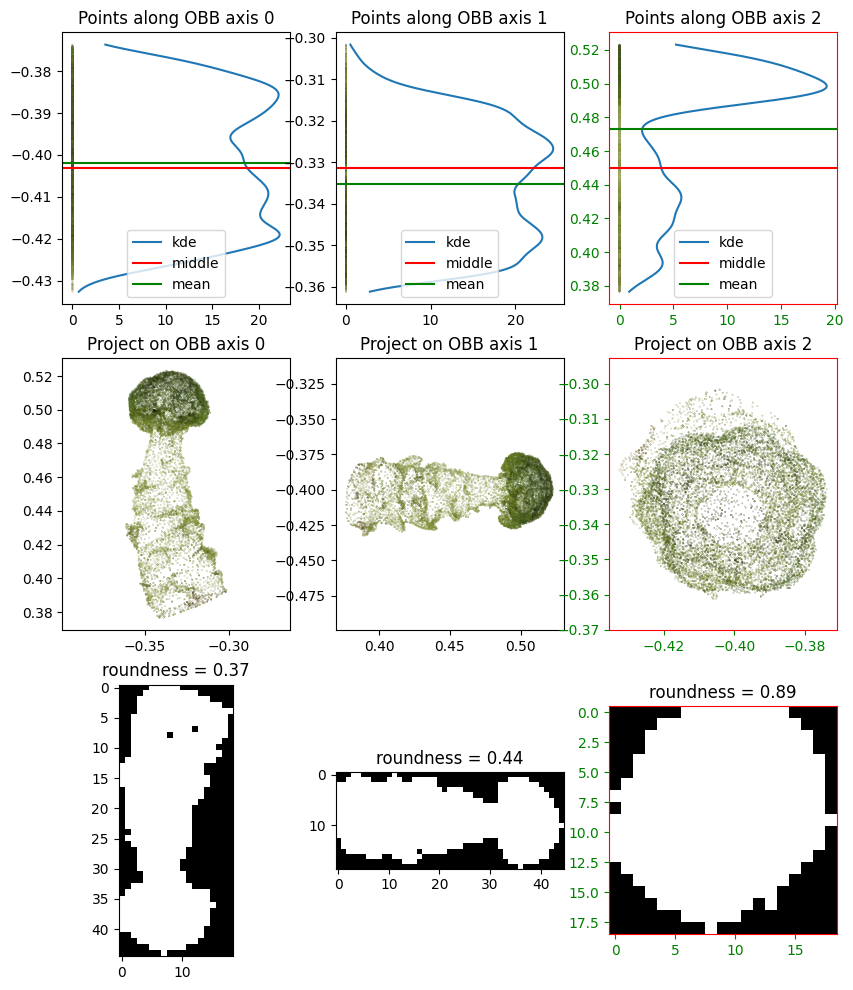

In [110]:
broccoli_id = '3-4'

bro_mesh = o3d.io.read_triangle_mesh(mesh_db[broccoli_id])

def_test_pcd = mesh2pcd(bro_mesh)

crown_pcd, crown_colored_pcd, crown_points_index = segment_crown(def_test_pcd, 10, 0.005, show_log=False)

rotated_pcd, R = rotate_to_z(crown_pcd, def_test_pcd, show=True)

In [111]:
mfinal = copy(bro_mesh).rotate(R, center=obb.center)

In [113]:
o3d.visualization.draw_geometries([mfinal, line_set])